# AI-Generated vs Real Image Detection — CNN Classifier

This notebook follows the same workflow as the Day 5 / Day 5_6 CNN notebooks (load data -> build CNN -> train -> evaluate -> save/reload), but adapted for a **real-world image folder dataset** instead of MNIST/Fashion-MNIST, and for **binary classification** (Real vs AI-generated) instead of 10-class digit/clothing classification.

**Steps:**
1. Download the dataset
2. Inspect the dataset (this is where we check if it's actually usable)
3. Set the dataset paths (confirmed structure: `dataset/real/` and `dataset/ai/`)
4. Build train/validation/test datasets
5. Visualize sample images
6. Preprocessing & performance pipeline
7. Data augmentation
8. Build the CNN
9. Compile
10. Train
11. Plot accuracy/loss
12. Evaluate on the test set
13. Confusion matrix & classification report
14. Visualize correct/incorrect predictions
15. Save the model
16. Inference function — predict on any single uploaded image
17. (Bonus) Feature map visualization
18. Notes on next steps

In [1]:
import os
import pathlib
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

import kagglehub

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


## Step 1: Download the dataset

This pulls the dataset to a local cache folder and gives us the path.

In [2]:
# Download latest version
path = kagglehub.dataset_download("malaxmels/ai-detection-dataset")
print("Path to dataset files:", path)

DATASET_ROOT = pathlib.Path(path)

Using Colab cache for faster access to the 'ai-detection-dataset' dataset.
Path to dataset files: /kaggle/input/ai-detection-dataset


## Step 2: Inspect the dataset (do this before trusting it)

This is the most important step. A CNN is only as good as the data it's trained on, so before writing a single line of model code, we need to know:

- **What the folder structure actually is** (are classes already split into train/test, or is it one big folder per class?)
- **How many images per class** — if one class has 10x more images than the other, the model will just learn to predict the majority class
- **How many images total** — a few hundred per class is workable for a small CNN with augmentation; a few dozen is not enough
- **Whether images look reasonable** — corrupted files, wildly inconsistent sizes, watermarks that leak the label, etc.

Run the cell below and actually read the output before moving on — don't just assume the dataset is fine.

In [3]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def summarize_directory(root, max_depth=3):
    root = pathlib.Path(root)
    print(f"Scanning: {root}\n")
    for dirpath, dirnames, filenames in os.walk(root):
        depth = len(pathlib.Path(dirpath).relative_to(root).parts)
        if depth > max_depth:
            dirnames[:] = []  # don't descend further
            continue
        images = [f for f in filenames if pathlib.Path(f).suffix.lower() in IMG_EXTS]
        indent = "  " * depth
        label = pathlib.Path(dirpath).name or str(root)
        print(f"{indent}{label}/  -> {len(images)} image file(s), {len(dirnames)} subfolder(s)")

summarize_directory(DATASET_ROOT)

Scanning: /kaggle/input/ai-detection-dataset

ai-detection-dataset/  -> 0 image file(s), 1 subfolder(s)
  dataset/  -> 0 image file(s), 2 subfolder(s)
    ai/  -> 32565 image file(s), 0 subfolder(s)
    real/  -> 23993 image file(s), 0 subfolder(s)


In [4]:
# Count images per leaf folder (folders that directly contain images) so we can spot class imbalance
from collections import Counter

leaf_counts = Counter()
for dirpath, dirnames, filenames in os.walk(DATASET_ROOT):
    images = [f for f in filenames if pathlib.Path(f).suffix.lower() in IMG_EXTS]
    if images:
        rel = pathlib.Path(dirpath).relative_to(DATASET_ROOT)
        leaf_counts[str(rel)] = len(images)

print("Images per folder that actually contains images:\n")
for folder, count in sorted(leaf_counts.items(), key=lambda x: -x[1]):
    print(f"{folder:50s} {count}")

total = sum(leaf_counts.values())
print(f"\nTotal images found: {total}")

Images per folder that actually contains images:

dataset/ai                                         32565
dataset/real                                       23993

Total images found: 56558


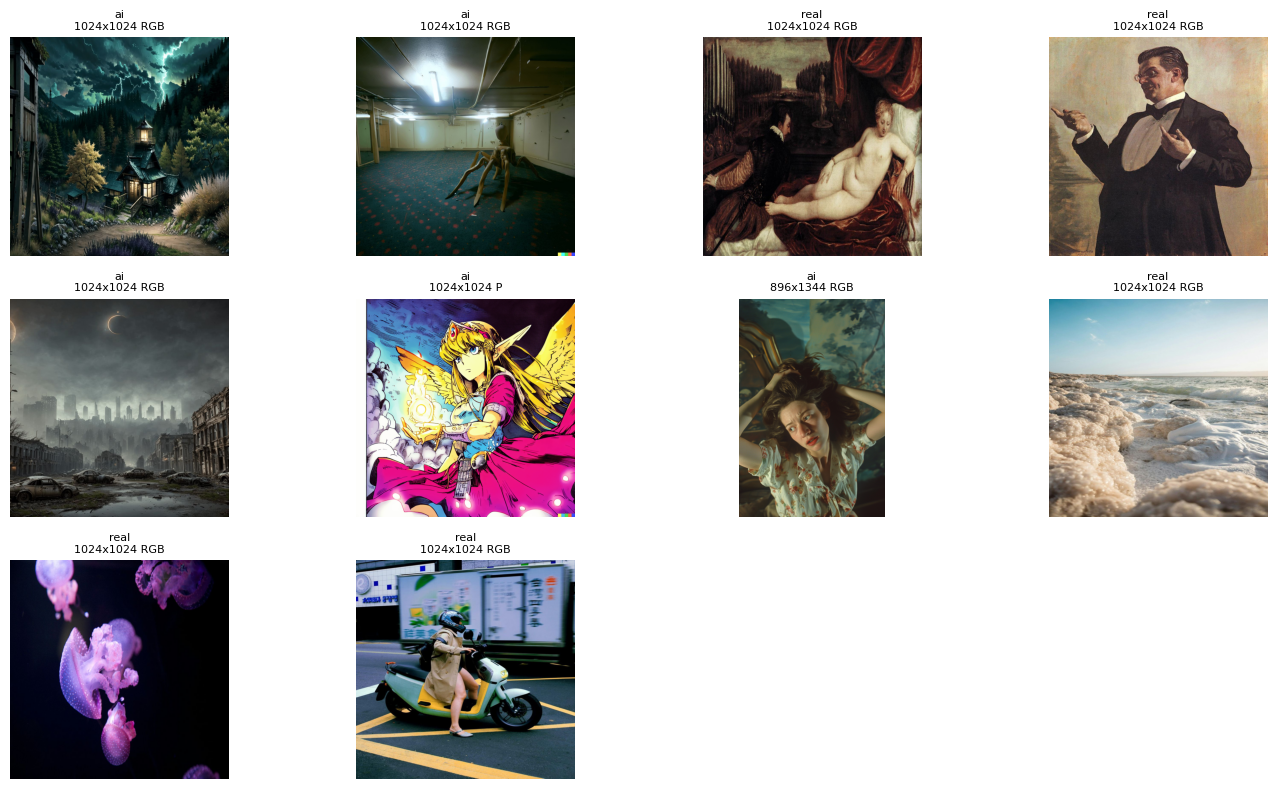


Sample image sizes (width, height): [(1024, 1024), (1024, 1024), (1024, 1024), (1024, 1024), (1024, 1024), (1024, 1024), (896, 1344), (1024, 1024), (1024, 1024), (1024, 1024)]


In [5]:
# Sanity-check a handful of actual image files: can they be opened, and what sizes/modes are they?
from PIL import Image
import random

sample_paths = []
for dirpath, dirnames, filenames in os.walk(DATASET_ROOT):
    images = [f for f in filenames if pathlib.Path(f).suffix.lower() in IMG_EXTS]
    for f in images[:5]:
        sample_paths.append(pathlib.Path(dirpath) / f)

random.shuffle(sample_paths)
sample_paths = sample_paths[:12]

sizes = []
plt.figure(figsize=(14, 8))
for i, p in enumerate(sample_paths):
    try:
        img = Image.open(p)
        sizes.append(img.size)
        plt.subplot(3, 4, i + 1)
        plt.imshow(img)
        plt.title(f"{p.parent.name}\n{img.size[0]}x{img.size[1]} {img.mode}", fontsize=8)
        plt.axis('off')
    except Exception as e:
        print(f"Could not open {p}: {e}")
plt.tight_layout()
plt.show()

print("\nSample image sizes (width, height):", sizes)

### Reading the output above — confirmed for this dataset

Checked against this specific `malaxmels/ai-detection-dataset`:

- [x] Two classes, `dataset/real/` (23,993 images) and `dataset/ai/` (32,565 images) — clear, unambiguous folder names
- [x] Class balance is ~42% real / 58% AI — mild imbalance, not severe. Handled below with `class_weight`
- [x] Plenty of images per class (tens of thousands) — no shortage of data
- [x] Images open fine and are almost entirely 1024x1024 JPEGs, with a handful of odd-sized ones mixed in on the AI side (fine, since everything gets resized anyway)
- [x] **Reused filenames checked manually** (e.g. `real/3377.jpg` and `ai/3377.jpg` both exist) — opening both side by side confirmed these are **unrelated images that coincidentally share a filename**, not a paired real/AI-generated-from-the-same-photo setup. No leakage concern there.
- [ ] **Still worth watching**: a scroll through `ai/` shows a mix of photorealistic AI images and clearly stylized/artistic ones (memes, glowing text, painterly portraits). The model will end up learning "AI-generated imagery in general" rather than specifically "photorealistic fakes designed to deceive" — worth a line in your write-up, not a blocker.

Since the structure is now known, we skip auto-detection and set the paths directly.

## Step 3: Set the dataset paths

The dataset root contains `dataset/real/` and `dataset/ai/` directly.

In [6]:
DATA_DIR = DATASET_ROOT / "dataset"
CLASS_NAMES = sorted(["ai", "real"])  # alphabetical order, matches Keras's inferred label order
print("Using DATA_DIR:", DATA_DIR)
print("Classes:", CLASS_NAMES)

assert (DATA_DIR / "ai").exists() and (DATA_DIR / "real").exists(), (
    "Expected 'ai' and 'real' subfolders under DATA_DIR — check DATASET_ROOT above if this fails."
)

Using DATA_DIR: /kaggle/input/ai-detection-dataset/dataset
Classes: ['ai', 'real']


## Step 4: Build train / validation / test datasets

`image_dataset_from_directory` reads images straight from folders, resizes them, batches them, and infers labels from the subfolder names — this is the standard Keras way to load an image classification dataset that's too large (or not shaped like MNIST) to load fully into memory as one array.

In [7]:
IMG_SIZE = (160, 160)   # bump this up (e.g. 224x224) later if your GPU/CPU can handle it
BATCH_SIZE = 16
SEED = 42

# 80% train, 20% validation, split off from DATA_DIR
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

class_names = train_ds.class_names
print("Class names (0/1 order used by the model):", class_names)

Found 56558 files belonging to 2 classes.
Using 45247 files for training.
Found 56558 files belonging to 2 classes.
Using 11311 files for validation.
Class names (0/1 order used by the model): ['ai', 'real']


In [8]:
# Carve a proper held-out test set out of the validation split (don't evaluate on data used to tune anything)
val_batches = tf.data.experimental.cardinality(val_ds)
test_ds = val_ds.take(val_batches // 2)
val_ds = val_ds.skip(val_batches // 2)

print("Train batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())

Train batches: 2828
Validation batches: 354
Test batches: 353


## Step 5: Visualize sample images

Always look at what's actually going into the model.

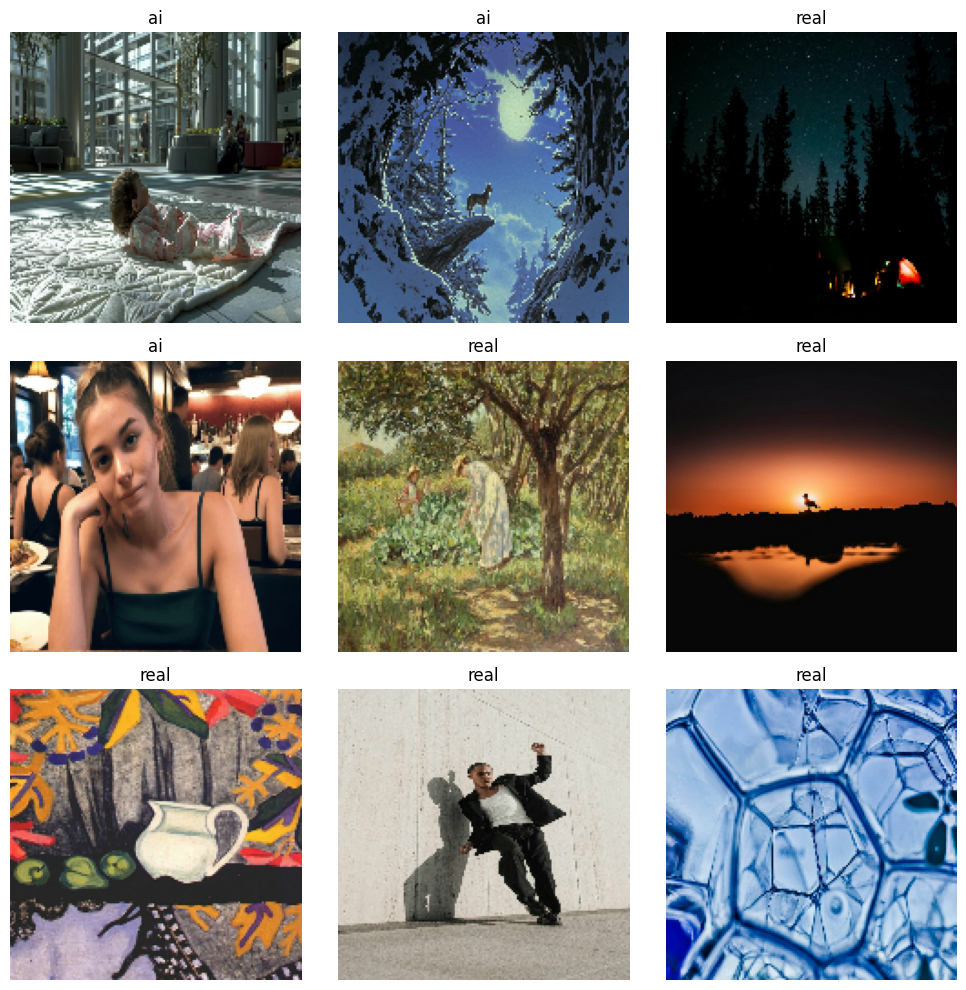

In [9]:
plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(min(9, images.shape[0])):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i][0])])
        plt.axis("off")
plt.tight_layout()
plt.show()

## Step 6: Preprocessing & performance pipeline

- **Rescaling**: pixel values start at 0-255, we scale to 0-1, same as `X_train / 255.0` in the MNIST notebook
- **Caching / prefetching**: keeps the GPU/CPU fed with the next batch while the current one trains, instead of stalling on disk reads

In [10]:
normalization_layer = layers.Rescaling(1./255)

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.shuffle(1000).prefetch(buffer_size=AUTOTUNE)

val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)

test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

## Step 7: Data augmentation

Real-vs-AI datasets are often small. Augmentation (random flips/rotations/zooms) artificially expands the training set and reduces overfitting, similar in spirit to why the Fashion-MNIST notebook used `Dropout`.

In [11]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
], name="data_augmentation")

print("Data augmentation layer created successfully.")

Data augmentation layer created successfully.


## Step 8: Build the CNN

Same block structure as the Fashion-MNIST notebook (Conv2D -> MaxPooling, repeated, then Flatten -> Dense -> Dropout), but:
- Input is 3-channel color (160, 160, 3) instead of grayscale (28, 28, 1)
- Output is a **single sigmoid unit** for binary classification instead of 10-way softmax
- Augmentation and rescaling are baked in as the first layers of the model

In [12]:
model = models.Sequential([
    layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3)),
    data_augmentation,
    normalization_layer,

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(1, activation='sigmoid')
], name="ai_image_detector")

model.summary()

Model: "ai_image_detector"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 158, 158, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 79, 79, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 77, 77, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 38, 38, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 36, 36, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 41472)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     5,308,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,401,921 (20.61 MB)

 Trainable params: 5,401,921 (20.61 MB)

 Non-trainable params: 0 (0.00 B)

## Step 9: Compile

Binary classification -> `binary_crossentropy` loss instead of `sparse_categorical_crossentropy`.

In [13]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

## Step 10: Train

`EarlyStopping` watches validation loss and stops training once the model stops improving, restoring the best weights -- this protects against overfitting.

Since the dataset is mildly imbalanced (32,565 AI vs. 23,993 real -> ~58%/42%), `class_weight` up-weights the minority ("real") class slightly so the model doesn't get a small bias toward predicting "AI" by default. Label order is alphabetical (`ai`=0, `real`=1), matching `CLASS_NAMES` from Step 3.

In [14]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    )
]

# 0 = ai (majority class, 32,565 images), 1 = real (minority class, 23,993 images)
class_weight = {0: 0.87, 1: 1.18}

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=11,
    callbacks=callbacks,
    class_weight=class_weight,
)

Epoch 1/11
2828/2828 ━━━━━━━━━━━━━━━━━━━━ 464s 117ms/step - accuracy: 0.7070 - loss: 0.5768 - val_accuracy: 0.7710 - val_loss: 0.4965
Epoch 2/11
2828/2828 ━━━━━━━━━━━━━━━━━━━━ 427s 111ms/step - accuracy: 0.7552 - loss: 0.5185 - val_accuracy: 0.7379 - val_loss: 0.5714
Epoch 3/11
2828/2828 ━━━━━━━━━━━━━━━━━━━━ 442s 111ms/step - accuracy: 0.7690 - loss: 0.4965 - val_accuracy: 0.7851 - val_loss: 0.4620
Epoch 4/11
2828/2828 ━━━━━━━━━━━━━━━━━━━━ 499s 136ms/step - accuracy: 0.7772 - loss: 0.4792 - val_accuracy: 0.7959 - val_loss: 0.4503
Epoch 5/11
2828/2828 ━━━━━━━━━━━━━━━━━━━━ 429s 111ms/step - accuracy: 0.7852 - loss: 0.4682 - val_accuracy: 0.7862 - val_loss: 0.4652
Epoch 6/11
2828/2828 ━━━━━━━━━━━━━━━━━━━━ 441s 113ms/step - accuracy: 0.7937 - loss: 0.4592 - val_accuracy: 0.7775 - val_loss: 0.4757
Epoch 7/11
2828/2828 ━━━━━━━━━━━━━━━━━━━━ 429s 111ms/step - accuracy: 0.7953 - loss: 0.4506 - val_accuracy: 0.8047 - val_loss: 0.4387
Epoch 8/11
2828/2828 ━━━━━━━━━━━━━━━━━━━━ 440s 115ms/step - ac

In [15]:
model.save("/content/ai_image_detector.keras")
print("Model saved!")
from google.colab import files

files.download("/content/ai_image_detector.keras")

Model saved!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 11: Plot training curves

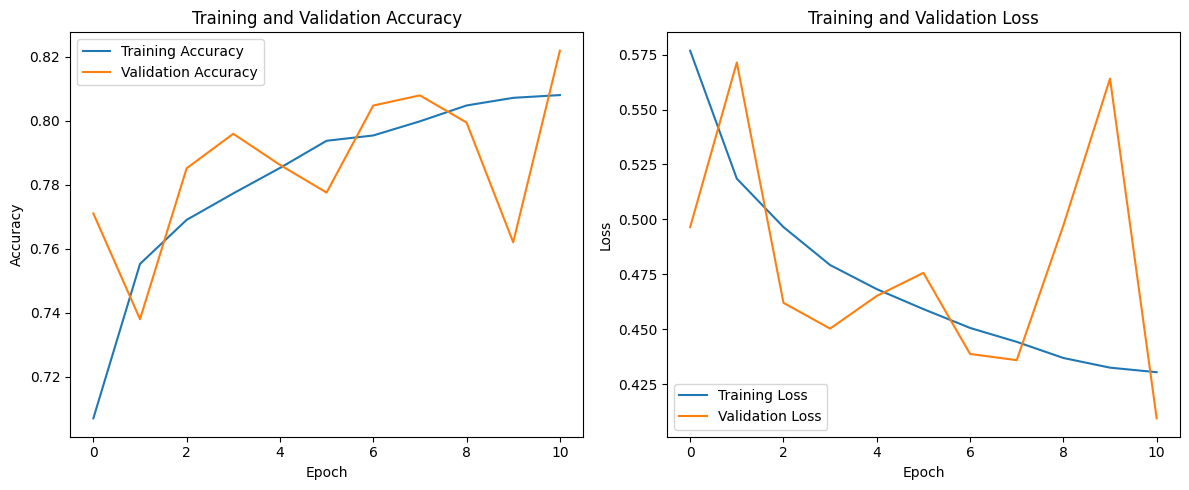

In [16]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()

plt.tight_layout()
plt.show()

### What to look for here

- Training and validation accuracy climbing together -> good
- Training accuracy near 100% while validation accuracy stalls much lower -> overfitting (more augmentation, more dropout, or more data needed)
- Both curves stuck near 50% -> the model isn't learning anything real; this is usually a data problem (Step 2 is worth revisiting), not a model problem

## Step 12: Evaluate on the held-out test set

In [17]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=0)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

Test Loss: 0.4187999963760376
Test Accuracy: 0.8238314390182495


## Step 13: Confusion matrix & classification report

353/353 ━━━━━━━━━━━━━━━━━━━━ 38s 107ms/step
Classification Report:

              precision    recall  f1-score   support

          ai       0.57      0.62      0.60      3260
        real       0.42      0.37      0.39      2388

    accuracy                           0.52      5648
   macro avg       0.50      0.50      0.50      5648
weighted avg       0.51      0.52      0.51      5648



<Figure size 700x600 with 0 Axes>

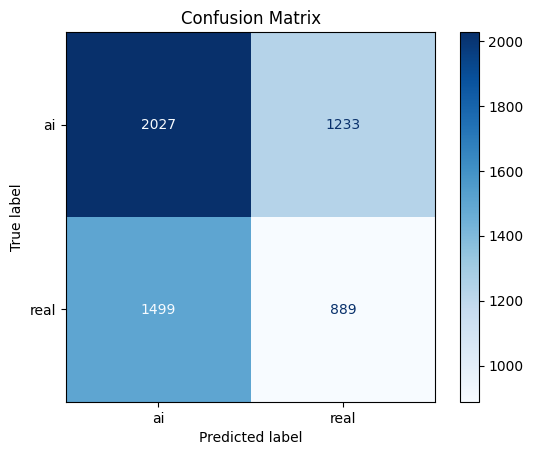

In [18]:
# Step 13: Confusion matrix & classification report

# Get true labels and predictions in a single pass to prevent dataset shuffling mismatches
y_true = []
y_pred_prob = []

for images, labels in test_ds:
    y_true.extend(labels.numpy().flatten())
    y_pred_prob.extend(model.predict(images, verbose=0).flatten())

y_true = np.array(y_true)
y_pred_prob = np.array(y_pred_prob)

# Convert probabilities to class predictions
y_pred = (y_pred_prob >= 0.5).astype(int)

print("Classification Report:\n")
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7, 6))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
disp.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

## Step 14: Look at what the model gets wrong

Inspecting misclassified images often reveals *why* a model is failing (e.g. always confusing a specific AI generator's style with real photos, or struggling with heavily compressed/low-res images).

In [ ]:
wrong_idx = np.where(y_pred != y_true)[0]
print("Incorrect predictions:", len(wrong_idx), "out of", len(y_true))

# Find incorrect predictions batch by batch to avoid loading all images into memory (prevents crashes!)
wrong_images = []
wrong_actual = []
wrong_predicted = []

for images, labels in test_ds:
    if len(wrong_images) >= 12:
        break
    true_lbls = labels.numpy().flatten()
    preds = model.predict(images, verbose=0).flatten()
    pred_lbls = (preds >= 0.5).astype(int)
    
    mismatches = np.where(pred_lbls != true_lbls)[0]
    for idx in mismatches:
        if len(wrong_images) < 12:
            wrong_images.append(images[idx].numpy())
            wrong_actual.append(class_names[int(true_lbls[idx])])
            wrong_predicted.append(class_names[int(pred_lbls[idx])])

plt.figure(figsize=(12, 8))
for i in range(len(wrong_images)):
    plt.subplot(3, 4, i + 1)
    plt.imshow(wrong_images[i].astype("uint8"))
    plt.title(f"Actual: {wrong_actual[i]}\nPredicted: {wrong_predicted[i]}", fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

Incorrect predictions: 2732 out of 5648


## Step 16: Predict on a single uploaded image

This is the actual "upload an image, get Real or AI-generated" behavior the project asks for. Point `predict_image` at any image file path.

In [ ]:
loaded_model = tf.keras.models.load_model("ai_image_detector.keras")

def predict_image(image_path, model=loaded_model, class_names=class_names, img_size=IMG_SIZE):
    img = tf.keras.utils.load_img(image_path, target_size=img_size)
    img_array = tf.keras.utils.img_to_array(img)
    img_array = tf.expand_dims(img_array, 0)  # add batch dimension (model handles rescaling internally)

    probability = model.predict(img_array, verbose=0)[0][0]
    predicted_class = class_names[int(probability >= 0.5)]
    confidence = probability if probability >= 0.5 else 1 - probability

    plt.figure(figsize=(4, 4))
    plt.imshow(img)
    plt.title(f"Prediction: {predicted_class}\nConfidence: {confidence:.2%}")
    plt.axis('off')
    plt.show()

    print(f"Predicted class: {predicted_class}")
    print(f"Confidence: {confidence:.2%}")
    print(f"Raw sigmoid output ({class_names[1]} probability): {probability:.4f}")

    return predicted_class, confidence

# Example usage — replace with a real path to try it:
# predict_image("/path/to/some_image.jpg")

## Step 17 (bonus): Visualize what the first conv layer is looking at

Same idea as the feature-map cell in the MNIST notebook — helps sanity-check that the network is picking up on real texture/artifact patterns rather than something spurious like a watermark or border.

In [ ]:
# Grab one real test image to inspect
sample_image = None
for images, _ in test_ds.take(1):
    sample_image = images[0].numpy()
    break

conv_layer_model = tf.keras.Model(
    inputs=model.inputs,
    outputs=model.get_layer(index=3).output  # first Conv2D layer (after augmentation + rescaling layers)
)

feature_maps = conv_layer_model.predict(np.expand_dims(sample_image, 0), verbose=0)
print("Feature map shape:", feature_maps.shape)

plt.figure(figsize=(12, 8))
for i in range(min(12, feature_maps.shape[-1])):
    plt.subplot(3, 4, i + 1)
    plt.imshow(feature_maps[0, :, :, i], cmap='viridis')
    plt.axis('off')
plt.suptitle("First Conv2D layer feature maps")
plt.tight_layout()
plt.show()

## Notes / next steps

- **If accuracy is disappointing (~50-65%)**: this is common for real-vs-AI detection trained from scratch on a small dataset. The next real upgrade is **transfer learning** — swap the custom CNN for a pretrained backbone like `MobileNetV2` or `EfficientNetB0` (via `tf.keras.applications`), freeze its weights, and add your own classification head on top. That typically gives a large accuracy jump with the same amount of data.
- **If the dataset is dominated by one AI generator** (e.g. only Midjourney or only Stable Diffusion images): the model will likely fail to generalize to AI images from other generators. Worth checking the dataset's description/discussion tab on Kaggle for what generated the "AI" images.
- **Image size**: `160x160` was used above to keep training fast. Increasing to `224x224` (standard for most pretrained models) usually helps once you move to transfer learning.
- **Deployment**: once you're happy with the model, `ai_image_detector.keras` + the `predict_image` function above is basically the whole "upload an image, get a prediction" pipeline — that function is what you'd wire up to a simple web upload form (e.g. Streamlit or Flask) if the project needs a front end.